In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report
import cv2
from PIL import Image

# TensorFlow imports
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping

In [2]:
# Configuration
class Config:
    DATASET_PATH = "Dataset"
    TRAIN_DIR = os.path.join(DATASET_PATH, "Train")
    VAL_DIR = os.path.join(DATASET_PATH, "Validation")
    TEST_DIR = os.path.join(DATASET_PATH, "Test")
    
    IMG_HEIGHT = 128
    IMG_WIDTH = 128
    IMG_CHANNELS = 3
    IMG_SHAPE = (IMG_HEIGHT, IMG_WIDTH, IMG_CHANNELS)
    
    BATCH_SIZE = 32
    EPOCHS = 30
    LEARNING_RATE = 0.001
    
    CLASS_NAMES = ['Fake', 'Real']
    MODEL_PATH = "deepfake_simple_model.h5"

config = Config()

In [3]:
def load_data():
    print("Chargement des données...")

    train_datagen = ImageDataGenerator(
        rescale=1./255,
        rotation_range=15,
        width_shift_range=0.1,
        height_shift_range=0.1,
        horizontal_flip=True
    )
    
    # Normalisation 
    val_test_datagen = ImageDataGenerator(rescale=1./255)
    
    train_gen = train_datagen.flow_from_directory(
        config.TRAIN_DIR,
        target_size=(config.IMG_HEIGHT, config.IMG_WIDTH),
        batch_size=config.BATCH_SIZE,
        class_mode='binary',
        shuffle=True
    )
    
    val_gen = val_test_datagen.flow_from_directory(
        config.VAL_DIR,
        target_size=(config.IMG_HEIGHT, config.IMG_WIDTH),
        batch_size=config.BATCH_SIZE,
        class_mode='binary',
        shuffle=False
    )
    
    test_gen = val_test_datagen.flow_from_directory(
        config.TEST_DIR,
        target_size=(config.IMG_HEIGHT, config.IMG_WIDTH),
        batch_size=config.BATCH_SIZE,
        class_mode='binary',
        shuffle=False
    )
    
    print(f"Entraînement: {train_gen.samples} images")
    print(f"Validation: {val_gen.samples} images")
    print(f"Test: {test_gen.samples} images")
    
    return train_gen, val_gen, test_gen


## Construction du modele

In [4]:
def build_simple_cnn():
    print("Construction du modèle CNN ")
    
    model = models.Sequential([
        # Bloc 1
        layers.Conv2D(32, (3, 3), activation='relu', 
                     input_shape=config.IMG_SHAPE, padding='same'),
        layers.MaxPooling2D((2, 2)),
        
        # Bloc 2
        layers.Conv2D(64, (3, 3), activation='relu', padding='same'),
        layers.MaxPooling2D((2, 2)),
        
        # Bloc 3
        layers.Conv2D(128, (3, 3), activation='relu', padding='same'),
        layers.MaxPooling2D((2, 2)),
        
        # Classification
        layers.Flatten(),
        layers.Dense(128, activation='relu'),
        layers.Dropout(0.5),
        layers.Dense(1, activation='sigmoid')
    ])
    
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=config.LEARNING_RATE),
        loss='binary_crossentropy',
        metrics=['accuracy']
    )
    
    print("Modèle construit!")
    model.summary()
    
    return model

In [5]:
def visualize_model(model):
    from tensorflow.keras.utils import plot_model
    plot_model(
        model, 
        to_file='model_architecture.png', 
        show_shapes=True, 
        show_layer_names=True
    )
    print("Architecture sauvegardée: model_architecture.png")

## Entraîne le modèle

In [6]:
def train_model(model, train_gen, val_gen):
    print("Début de l'entraînement...")
    callbacks = [
        EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True),
        ModelCheckpoint(config.MODEL_PATH, monitor='val_accuracy', save_best_only=True)
    ]
    
    history = model.fit(
        train_gen,
        epochs=config.EPOCHS,
        validation_data=val_gen,
        callbacks=callbacks,
        verbose=1
    )
    
    print("Entraînement terminé!")
    return history

In [7]:
def plot_history(history):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
    
    # Accuracy
    ax1.plot(history.history['accuracy'], label='Train', linewidth=2)
    ax1.plot(history.history['val_accuracy'], label='Validation', linewidth=2)
    ax1.set_title('Accuracy', fontsize=14, fontweight='bold')
    ax1.set_xlabel('Epoch')
    ax1.set_ylabel('Accuracy')
    ax1.legend()
    ax1.grid(True, alpha=0.3)
    
    # Loss
    ax2.plot(history.history['loss'], label='Train', linewidth=2)
    ax2.plot(history.history['val_loss'], label='Validation', linewidth=2)
    ax2.set_title('Loss', fontsize=14, fontweight='bold')
    ax2.set_xlabel('Epoch')
    ax2.set_ylabel('Loss')
    ax2.legend()
    ax2.grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.savefig('training_history.png', dpi=150)
    plt.show()
    print("Graphiques sauvegardés: training_history.png")


## Evaluation

In [8]:
def evaluate_model(model, test_gen):
    """Évalue le modèle sur le dataset de test"""
    print("Évaluation du modèle...")
    
    # Prédictions
    test_gen.reset()
    predictions = model.predict(test_gen, verbose=1)
    predicted_classes = (predictions > 0.5).astype(int).flatten()
    true_classes = test_gen.classes[:len(predicted_classes)]
    
    # Métriques
    test_loss, test_accuracy = model.evaluate(test_gen, verbose=0)
    
    print("\n" + "="*60)
    print("RÉSULTATS")
    print("="*60)
    print(f"Accuracy: {test_accuracy:.4f} ({test_accuracy*100:.2f}%)")
    print(f"Loss: {test_loss:.4f}")
    print("="*60 + "\n")
    
    # Matrice de confusion
    cm = confusion_matrix(true_classes, predicted_classes)
    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
                xticklabels=config.CLASS_NAMES,
                yticklabels=config.CLASS_NAMES)
    plt.title('Matrice de Confusion', fontsize=16, fontweight='bold')
    plt.ylabel('Vraie classe')
    plt.xlabel('Classe prédite')
    plt.tight_layout()
    plt.savefig('confusion_matrix.png', dpi=150)
    plt.show()
    
    # Rapport détaillé
    print("Rapport de classification:")
    print(classification_report(true_classes, predicted_classes, 
                               target_names=config.CLASS_NAMES))
    
    return {'accuracy': test_accuracy, 'loss': test_loss}

In [9]:
def main():
    # Charger les données
    train_gen, val_gen, test_gen = load_data()
    
    # Construire le modèle
    model = build_simple_cnn()
    
    # Visualiser l'architecture
    visualize_model(model)
    
    # Entraîner
    history = train_model(model, train_gen, val_gen)
    
    # Visualiser l'entraînement
    plot_history(history)
    
    # Évaluer
    metrics = evaluate_model(model, test_gen)
    
    print(f"\nModèle sauvegardé: {config.MODEL_PATH}")

    return model, history, metrics

Chargement des données...
Found 50000 images belonging to 2 classes.
Found 13992 images belonging to 2 classes.
Found 2740 images belonging to 2 classes.
Entraînement: 50000 images
Validation: 13992 images
Test: 2740 images
Construction du modèle CNN 
Modèle construit!


C:\Users\AdMin\deepfake_env\lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 128, 128, 32)        │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 64, 64, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 64, 64, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 32, 32, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_2 (Conv2D)                    │ (None, 32, 32, 128)         │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_2 (MaxPooling2D)       │ (None, 16, 16, 128)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 32768)               │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 128)                 │       4,194,432 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 1)                   │             129 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 4,287,809 (16.36 MB)

...

1563/1563 ━━━━━━━━━━━━━━━━━━━━ 399s 255ms/step - accuracy: 0.8829 - loss: 0.2850 - val_accuracy: 0.9132 - val_loss: 0.2098
Epoch 7/30
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 391s 250ms/step - accuracy: 0.8904 - loss: 0.2713 - val_accuracy: 0.9095 - val_loss: 0.2164
Epoch 8/30
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 388s 248ms/step - accuracy: 0.8939 - loss: 0.2597 - val_accuracy: 0.9067 - val_loss: 0.2272
Epoch 9/30
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 0s 234ms/step - accuracy: 0.8981 - loss: 0.2547  

1563/1563 ━━━━━━━━━━━━━━━━━━━━ 391s 250ms/step - accuracy: 0.9010 - loss: 0.2479 - val_accuracy: 0.9161 - val_loss: 0.2069
Epoch 10/30
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 0s 236ms/step - accuracy: 0.8995 - loss: 0.2450  

1563/1563 ━━━━━━━━━━━━━━━━━━━━ 395s 253ms/step - accuracy: 0.9014 - loss: 0.2429 - val_accuracy: 0.9192 - val_loss: 0.2043
Epoch 11/30
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 392s 251ms/step - accuracy: 0.9049 - loss: 0.2331 - val_accuracy: 0.9187 - val_loss: 0.1983
Epoch 12/30
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 0s 465ms/step - accuracy: 0.9080 - loss: 0.2263  

1563/1563 ━━━━━━━━━━━━━━━━━━━━ 847s 542ms/step - accuracy: 0.9085 - loss: 0.2251 - val_accuracy: 0.9265 - val_loss: 0.1843
Epoch 13/30
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 468s 300ms/step - accuracy: 0.9112 - loss: 0.2206 - val_accuracy: 0.8874 - val_loss: 0.2896
Epoch 14/30
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 406s 259ms/step - accuracy: 0.9124 - loss: 0.2166 - val_accuracy: 0.9159 - val_loss: 0.2111
Epoch 15/30
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 390s 250ms/step - accuracy: 0.9155 - loss: 0.2106 - val_accuracy: 0.9263 - val_loss: 0.1888
Epoch 16/30
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 0s 232ms/step - accuracy: 0.9181 - loss: 0.2039  

1563/1563 ━━━━━━━━━━━━━━━━━━━━ 390s 249ms/step - accuracy: 0.9175 - loss: 0.2053 - val_accuracy: 0.9317 - val_loss: 0.1751
Epoch 17/30
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 401s 256ms/step - accuracy: 0.9180 - loss: 0.2037 - val_accuracy: 0.9220 - val_loss: 0.2312
Epoch 18/30
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 500s 320ms/step - accuracy: 0.9222 - loss: 0.1950 - val_accuracy: 0.9214 - val_loss: 0.1914
Epoch 19/30
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 489s 313ms/step - accuracy: 0.9213 - loss: 0.1963 - val_accuracy: 0.9084 - val_loss: 0.2599
Epoch 20/30
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 493s 315ms/step - accuracy: 0.9235 - loss: 0.1920 - val_accuracy: 0.9292 - val_loss: 0.1839
Epoch 21/30
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 397s 254ms/step - accuracy: 0.9249 - loss: 0.1907 - val_accuracy: 0.9302 - val_loss: 0.1918
Entraînement terminé!


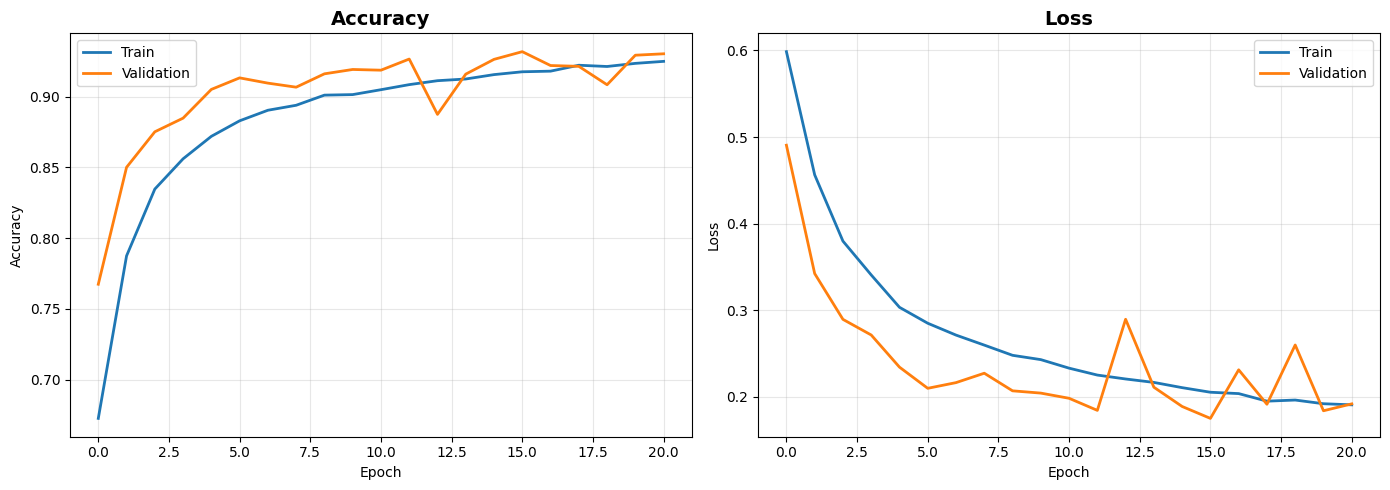

Graphiques sauvegardés: training_history.png
Évaluation du modèle...
86/86 ━━━━━━━━━━━━━━━━━━━━ 24s 275ms/step

RÉSULTATS
Accuracy: 0.8723 (87.23%)
Loss: 0.3336



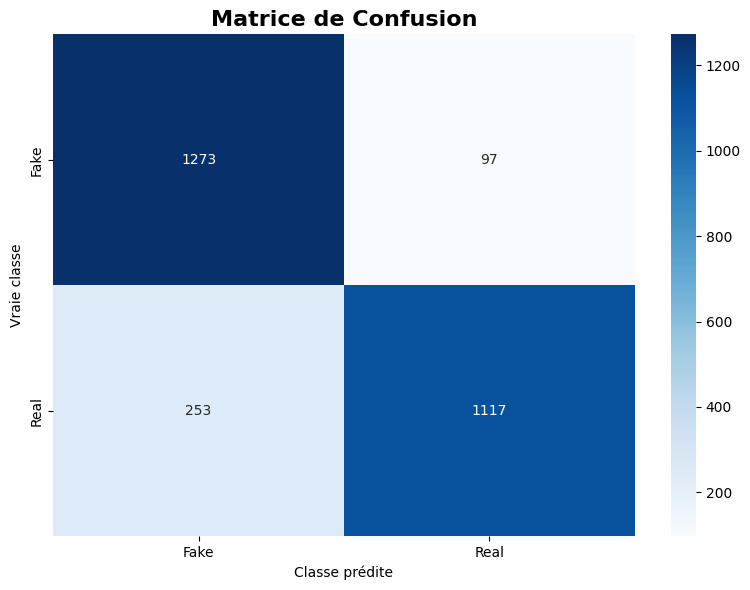

Rapport de classification:
              precision    recall  f1-score   support

        Fake       0.83      0.93      0.88      1370
        Real       0.92      0.82      0.86      1370

    accuracy                           0.87      2740
   macro avg       0.88      0.87      0.87      2740
weighted avg       0.88      0.87      0.87      2740


Modèle sauvegardé: deepfake_simple_model.h5


In [10]:
if __name__ == "__main__":
    model, history, metrics = main()